# 🖋️ Pitman Shorthand OCR — Complete Training Pipeline (Google Colab)

> **Run on Colab with T4 GPU.** Download trained models at the end → use in VSCode.

## The Key Challenge
This dataset has **~15,000 unique words with only 1 image each**.  
A normal classifier (15K classes, 1 sample each) **cannot work**.

## Our Solution: 3-Strategy Approach

### Strategy 1: Heavy Augmentation (50x data multiplication)
Generate 50 augmented versions of each image → 750K training samples.
Elastic distortion, morphological changes, rotation, noise — simulates handwriting variation.

### Strategy 2: Metric Learning (Siamese/Triplet Network)  
Instead of classifying, learn an **embedding space** where similar symbols are close.
At inference, compare the input against all 15K stored embeddings → nearest neighbor = answer.
Works with 1 sample per class!

### Strategy 3: Image-to-Sequence (CNN → Transformer decoder)
Treat the word label as a **character sequence**. The model learns to "read" strokes
as characters (p-i-t-m-a-n). Shares knowledge across words with common substrings.
"abandon" and "abandonment" share stroke patterns → model generalizes.

We train **all three** and ensemble them for maximum accuracy.

### Pipeline
```
Step 1: Setup & Download Dataset
Step 2: EDA
Step 3: Heavy Preprocessing + 50x Augmentation
Step 4: Strategy 1 — Classifier with Augmented Data
Step 5: Strategy 2 — Metric Learning (Siamese Network)  
Step 6: Strategy 3 — Image-to-Sequence (CNN + Transformer)
Step 7: Ensemble & Evaluate
Step 8: Generate Sentence Dataset
Step 9: Test Full Pipeline
Step 10: Download Models
```

⚡ **Before running:** Runtime → Change runtime type → **T4 GPU**

---
## Step 1: Setup & Install

In [ ]:
# Check GPU
!nvidia-smi
import torch
print(f'PyTorch: {torch.__version__}')
print(f'CUDA: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB')

Wed Apr  1 07:18:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   31C    P0             46W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:
!pip install timm albumentations kaggle opencv-python-headless -q

import os, sys, json, time, csv, random, shutil
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter
from tqdm import tqdm
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2

print('✅ All imports ready')

✅ All imports ready


In [ ]:
# Directories
for d in ['data/raw', 'data/processed/symbols', 'data/augmented', 'data/sentences/images', 'models']:
    os.makedirs(d, exist_ok=True)

# GPU config
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = torch.cuda.is_available()
scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

if torch.cuda.is_available():
    gpu_mem = torch.cuda.get_device_properties(0).total_memory / 1024**3
    # Auto-scale batch size to GPU VRAM
    if gpu_mem >= 40:      # A100 80GB / 40GB
        BATCH_SIZE = 1024
    elif gpu_mem >= 20:    # L4 24GB
        BATCH_SIZE = 256
    elif gpu_mem >= 12:    # T4 16GB
        BATCH_SIZE = 128
    elif gpu_mem >= 6:     # GTX 1650 etc
        BATCH_SIZE = 32
    else:
        BATCH_SIZE = 16
else:
    BATCH_SIZE = 16

NUM_WORKERS = 2
print(f'Device: {device} | Batch: {BATCH_SIZE}')

Device: cuda | Batch: 256


---
## Step 2: Download Kaggle Dataset

In [ ]:
from google.colab import files
print('Upload your kaggle.json:')
uploaded = files.upload()
!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ 2>/dev/null; chmod 600 ~/.kaggle/kaggle.json
print('✅ Kaggle API key set')

Upload your kaggle.json:


Saving kaggle (1).json to kaggle (1).json
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
✅ Kaggle API key set


In [ ]:
!kaggle datasets download -d benthecoder/shorthand -p data/raw --unzip

raw_dir = Path('data/raw')
image_files = sorted(list(raw_dir.rglob('*.png')) + list(raw_dir.rglob('*.jpg')) + list(raw_dir.rglob('*.jpeg')))
print(f'\n✅ Downloaded {len(image_files)} images')
for f in image_files[:10]: print(f'  {f.name}')

Dataset URL: https://www.kaggle.com/datasets/benthecoder/shorthand
License(s): unknown
100% 48.7M/48.7M [00:00<00:00, 154MB/s]


✅ Downloaded 15280 images
  aback.png
  abaft.png
  abandon.png
  abandonment.png
  abase.png
  abashed.png
  abate.png
  abatement.png
  abberant.png
  abberation.png


---
## Step 3: Quick EDA

Images: 15280 | Unique labels: 15280
Width: 81 median | Height: 43 median

⚠️  15280 classes with ONLY 1 image each!
   This is a one-shot learning problem — standard classifiers fail here.


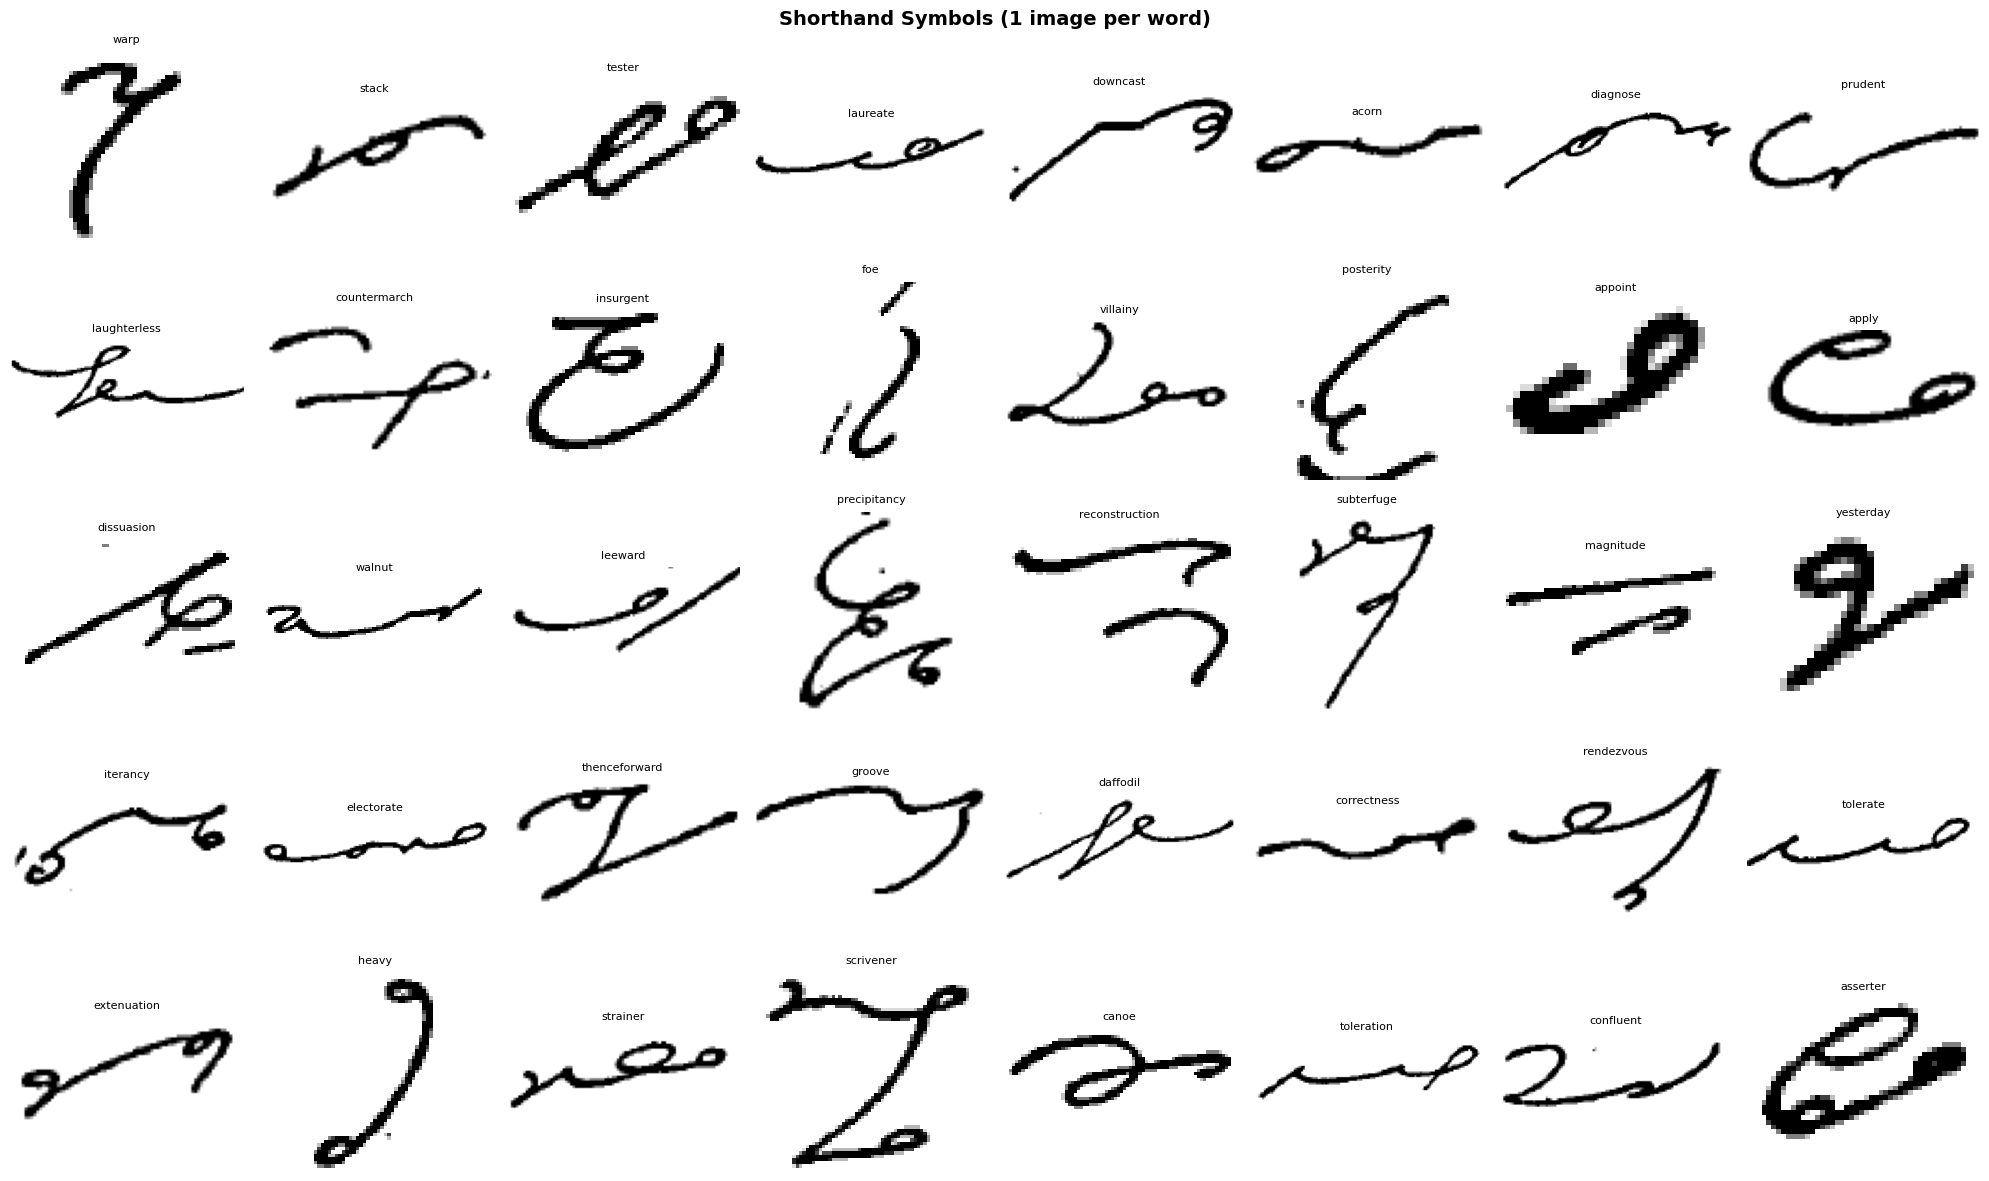

In [ ]:
widths, heights, labels = [], [], []
for fpath in image_files:
    img = cv2.imread(str(fpath), cv2.IMREAD_GRAYSCALE)
    if img is None: continue
    h, w = img.shape
    widths.append(w); heights.append(h)
    labels.append(fpath.stem.lower())

print(f'Images: {len(widths)} | Unique labels: {len(set(labels))}')
print(f'Width: {np.median(widths):.0f} median | Height: {np.median(heights):.0f} median')
print(f'\n⚠️  {len(set(labels))} classes with ONLY 1 image each!')
print('   This is a one-shot learning problem — standard classifiers fail here.')

fig, axes = plt.subplots(5, 8, figsize=(20, 12))
rng = np.random.RandomState(42)
for ax, idx in zip(axes.flat, rng.choice(len(image_files), 40, replace=False)):
    img = cv2.imread(str(sorted(image_files)[idx]), cv2.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap='gray'); ax.set_title(sorted(image_files)[idx].stem, fontsize=8); ax.axis('off')
plt.suptitle('Shorthand Symbols (1 image per word)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

---
## Step 4: Preprocessing + 50x Augmentation

Since we have only 1 image per class, we generate **50 augmented copies** of each image.  
This gives us ~750,000 training images with realistic handwriting variation.

In [ ]:
# ============================================
# PREPROCESSING
# ============================================
IMG_H, IMG_W = 64, 128

def preprocess_symbol(image_path, target_h=IMG_H, target_w=IMG_W):
    img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    if img is None: raise ValueError(f'Cannot load {image_path}')
    # Adaptive binarization
    binary = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv2.THRESH_BINARY_INV, blockSize=11, C=5)
    # Remove small noise (preserve dots!)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2, 2))
    cleaned = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=1)
    # Crop to content
    coords = cv2.findNonZero(cleaned)
    if coords is not None:
        x, y, w, h = cv2.boundingRect(coords)
        p = 5
        cleaned = cleaned[max(0,y-p):y+h+p, max(0,x-p):x+w+p]
    # Resize preserving aspect ratio + center pad
    h, w = cleaned.shape
    scale = min(target_h/h, target_w/w)
    nh, nw = int(h*scale), int(w*scale)
    resized = cv2.resize(cleaned, (nw, nh), interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR)
    result = np.zeros((target_h, target_w), dtype=np.uint8)
    yy, xx = (target_h-nh)//2, (target_w-nw)//2
    result[yy:yy+nh, xx:xx+nw] = resized
    return result

# Heavy augmentation pipeline for data multiplication
augmentation_pipeline = A.Compose([
    A.ShiftScaleRotate(shift_limit=0.08, scale_limit=0.15, rotate_limit=8,
                       border_mode=cv2.BORDER_CONSTANT, value=0, p=0.8),
    A.ElasticTransform(alpha=20, sigma=4, p=0.5),
    A.GridDistortion(num_steps=5, distort_limit=0.15, p=0.4),
    A.OpticalDistortion(distort_limit=0.1, shift_limit=0.1, p=0.3),
    A.Morphological(scale=(2, 3), operation='dilation', p=0.2),
    A.Morphological(scale=(2, 3), operation='erosion', p=0.2),
    A.GaussNoise(std_range=(0.02, 0.08), p=0.4),
    A.GaussianBlur(blur_limit=(3, 5), p=0.3),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.3),
])

print('✅ Preprocessing & augmentation defined')

✅ Preprocessing & augmentation defined


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_880/740650674.py:33: UserWarning: Argument(s) 'value' are not valid for transform ShiftScaleRotate
  A.ShiftScaleRotate(shift_limit=0.08, scale_limit=0.15, rotate_limit=8,
/tmp/ipykernel_880/740650674.py:37: UserWarning: Argument(s) 'shift_limit' are not valid for transform OpticalDistortion
  A.OpticalDistortion(distort_limit=0.1, shift_limit=0.1, p=0.3),


In [ ]:
# Process all images + generate augmentations
NUM_AUGMENTATIONS = 50  # 50 copies per image → ~750K total
AUG_DIR = Path('data/augmented')

label_to_idx = {}
total_generated = 0

for fpath in tqdm(sorted(image_files), desc='Processing + Augmenting'):
    try:
        label = fpath.stem.lower()
        processed = preprocess_symbol(str(fpath))

        if label not in label_to_idx:
            label_to_idx[label] = len(label_to_idx)
        idx = label_to_idx[label]

        # Save original
        cv2.imwrite(str(AUG_DIR / f'{idx:05d}_{label}_orig.png'), processed)
        total_generated += 1

        # Generate augmented copies
        for aug_i in range(NUM_AUGMENTATIONS):
            augmented = augmentation_pipeline(image=processed)['image']
            cv2.imwrite(str(AUG_DIR / f'{idx:05d}_{label}_aug{aug_i:03d}.png'), augmented)
            total_generated += 1

    except Exception as e:
        pass  # Skip corrupted files

num_classes = len(label_to_idx)
idx_to_label = {str(v): k for k, v in label_to_idx.items()}

with open('data/processed/label_to_idx.json', 'w') as f: json.dump(label_to_idx, f)
with open('data/processed/idx_to_label.json', 'w') as f: json.dump(idx_to_label, f)

print(f'\n✅ Generated {total_generated:,} images from {num_classes} classes')
print(f'   That\'s ~{total_generated/num_classes:.0f} images per class')

Processing + Augmenting: 100%|██████████| 15280/15280 [17:51<00:00, 14.26it/s]


✅ Generated 779,280 images from 15280 classes
   That's ~51 images per class


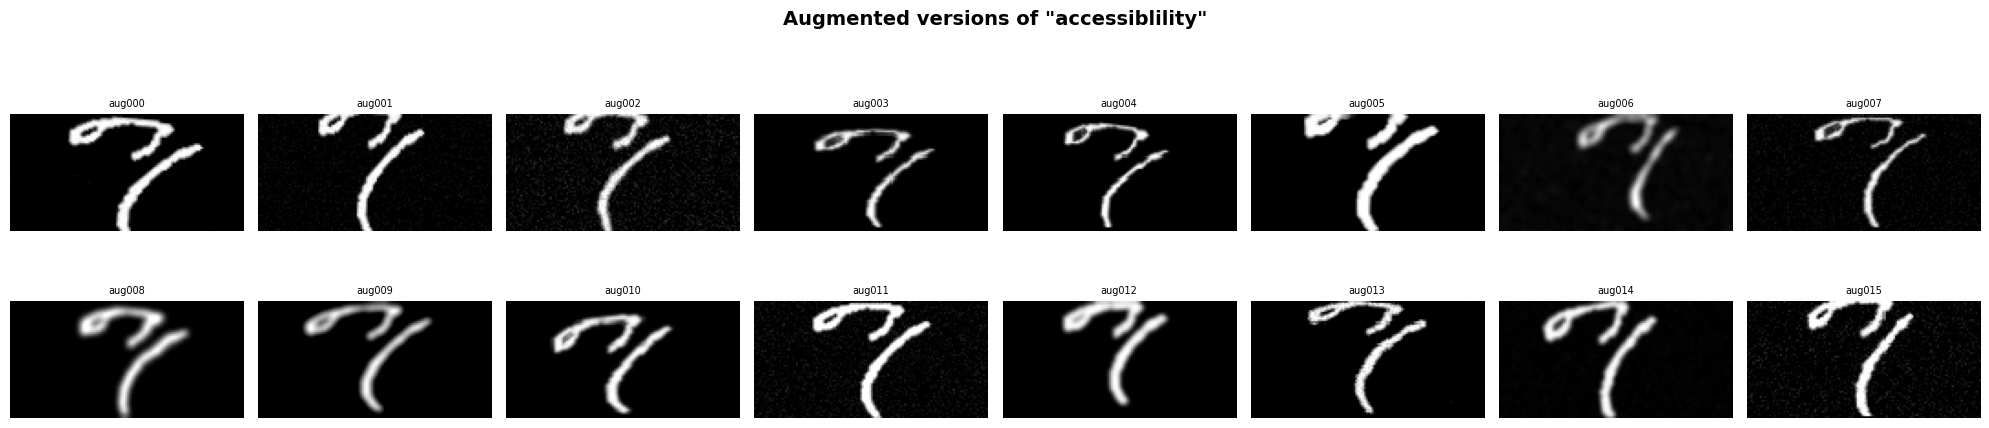

In [ ]:
# Visualize augmentations for one symbol
sample_label = sorted(label_to_idx.keys())[100]  # Pick one word
sample_idx = label_to_idx[sample_label]
sample_files = sorted(AUG_DIR.glob(f'{sample_idx:05d}_{sample_label}_*.png'))[:16]

fig, axes = plt.subplots(2, 8, figsize=(20, 5))
fig.suptitle(f'Augmented versions of "{sample_label}"', fontsize=14, fontweight='bold')
for ax, fpath in zip(axes.flat, sample_files):
    img = cv2.imread(str(fpath), cv2.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap='gray'); ax.axis('off')
    tag = 'ORIG' if 'orig' in fpath.name else fpath.name.split('_')[-1].replace('.png','')
    ax.set_title(tag, fontsize=7)
plt.tight_layout(); plt.show()

---
## Step 5: Strategy 1 — EfficientNet Classifier (with 50x augmented data)

Now with ~750K images instead of 15K, a standard classifier can actually learn.

In [ ]:
# Dataset class
class AugmentedSymbolDataset(Dataset):
    def __init__(self, root_dir, label_to_idx, transform=None, img_h=64, img_w=128):
        self.transform = transform
        self.img_h, self.img_w = img_h, img_w
        self.label_to_idx = label_to_idx
        self.samples = []
        for fname in sorted(os.listdir(root_dir)):
            if not fname.endswith('.png'): continue
            parts = fname.split('_', 2)  # idx_label_augN.png
            if len(parts) >= 2:
                idx_str = parts[0]
                # Extract label: everything between first _ and last _augN or _orig
                rest = fname[len(idx_str)+1:].replace('.png', '')
                if '_aug' in rest:
                    label = rest[:rest.rfind('_aug')]
                elif '_orig' in rest:
                    label = rest[:rest.rfind('_orig')]
                else:
                    label = rest
                if label in label_to_idx:
                    self.samples.append((os.path.join(root_dir, fname), label))
        print(f'[Dataset] {len(self.samples)} images, {len(label_to_idx)} classes')

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        filepath, label = self.samples[idx]
        img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
        if img is None: img = np.zeros((self.img_h, self.img_w), dtype=np.uint8)
        if img.shape[:2] != (self.img_h, self.img_w):
            img = cv2.resize(img, (self.img_w, self.img_h))
        img_3ch = np.stack([img, img, img], axis=-1)
        if self.transform:
            img_tensor = self.transform(image=img_3ch)['image']
        else:
            img_tensor = torch.from_numpy(img_3ch.astype(np.float32)/255.0).permute(2,0,1)
        return img_tensor, self.label_to_idx[label]

# Transforms (lighter now since augmentation is already baked into files)
train_tf = A.Compose([
    A.ShiftScaleRotate(shift_limit=0.03, scale_limit=0.05, rotate_limit=3,
                       border_mode=cv2.BORDER_CONSTANT, value=0, p=0.3),
    A.Normalize(mean=[0.5,0.5,0.5], std=[0.5,0.5,0.5]),
    ToTensorV2(),
])
val_tf = A.Compose([
    A.Normalize(mean=[0.5,0.5,0.5], std=[0.5,0.5,0.5]),
    ToTensorV2(),
])

/tmp/ipykernel_880/4044036981.py:42: UserWarning: Argument(s) 'value' are not valid for transform ShiftScaleRotate
  A.ShiftScaleRotate(shift_limit=0.03, scale_limit=0.05, rotate_limit=3,


In [ ]:
# Create dataset and splits
full_dataset = AugmentedSymbolDataset(str(AUG_DIR), label_to_idx, transform=None)

n = len(full_dataset)
n_train = int(0.85 * n)
n_val = int(0.10 * n)
n_test = n - n_train - n_val

train_set, val_set, test_set = random_split(full_dataset, [n_train, n_val, n_test],
                                             generator=torch.Generator().manual_seed(42))

class WrapTransform(Dataset):
    def __init__(self, subset, transform):
        self.subset, self.transform = subset, transform
    def __len__(self): return len(self.subset)
    def __getitem__(self, idx):
        img_t, label = self.subset[idx]
        img_np = (img_t.permute(1,2,0).numpy()*255).astype(np.uint8)
        return self.transform(image=img_np)['image'], label

train_data = WrapTransform(train_set, train_tf)
val_data = WrapTransform(val_set, val_tf)
test_data = WrapTransform(test_set, val_tf)

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True, drop_last=True)
val_loader = DataLoader(val_data, batch_size=min(BATCH_SIZE*2, 2048), shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
test_loader = DataLoader(test_data, batch_size=min(BATCH_SIZE*2, 2048), shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

print(f'Train: {len(train_data):,} | Val: {len(val_data):,} | Test: {len(test_data):,}')
print(f'Batches/epoch: {len(train_loader):,}')

[Dataset] 779280 images, 15280 classes
Train: 662,388 | Val: 77,928 | Test: 38,964
Batches/epoch: 2,587


In [ ]:
# Model
class SymbolClassifier(nn.Module):
    def __init__(self, num_classes, dropout=0.4, backbone='efficientnet_b0'):
        super().__init__()
        self.backbone = timm.create_model(backbone, pretrained=True, num_classes=0, in_chans=3)
        with torch.no_grad():
            feat_dim = self.backbone(torch.randn(1,3,64,128)).shape[1]
        self.classifier = nn.Sequential(
            nn.BatchNorm1d(feat_dim),
            nn.Dropout(dropout),
            nn.Linear(feat_dim, 1024),
            nn.GELU(),
            nn.BatchNorm1d(1024),
            nn.Dropout(dropout * 0.5),
            nn.Linear(1024, num_classes)
        )
        print(f'[Classifier] feat={feat_dim} → 1024 → {num_classes} classes')

    def forward(self, x):
        return self.classifier(self.backbone(x))

    def get_embedding(self, x):
        with torch.no_grad():
            return self.backbone(x)

model = SymbolClassifier(num_classes=num_classes, dropout=0.4).to(device)
print(f'Params: {sum(p.numel() for p in model.parameters()):,}')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

[Classifier] feat=1280 → 1024 → 15280 classes
Params: 20,985,900


In [ ]:
# Training setup
NUM_EPOCHS = 8  # Less epochs needed with more data
LR = 1e-3
PATIENCE = 5

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR,
                                           steps_per_epoch=len(train_loader),
                                           epochs=NUM_EPOCHS, pct_start=0.1)

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0.0
patience_counter = 0

In [ ]:
def train_epoch(model, loader, criterion, optimizer, scheduler, scaler, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in tqdm(loader, desc='Train', leave=False):
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad()
        with torch.amp.autocast('cuda', enabled=USE_AMP):
            outputs = model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer); scaler.update()
        scheduler.step()
        total_loss += loss.item() * images.size(0)
        _, pred = outputs.max(1)
        correct += pred.eq(labels).sum().item()
        total += labels.size(0)
    return total_loss/total, correct/total

@torch.no_grad()
def validate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        with torch.amp.autocast('cuda', enabled=USE_AMP):
            outputs = model(images); loss = criterion(outputs, labels)
        total_loss += loss.item() * images.size(0)
        _, pred = outputs.max(1)
        correct += pred.eq(labels).sum().item()
        total += labels.size(0)
    return total_loss/total, correct/total

In [ ]:
# 🚀 TRAIN!
print(f'Training on {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}')
print(f'Classes: {num_classes:,} | Images: {len(train_data):,} | Batch: {BATCH_SIZE}')
print(f'FP16: {USE_AMP} | Epochs: {NUM_EPOCHS}')
print('=' * 70)

for epoch in range(NUM_EPOCHS):
    start = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, scheduler, scaler, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)
    elapsed = time.time() - start

    history['train_loss'].append(train_loss); history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc); history['val_acc'].append(val_acc)

    vram = f" | VRAM: {torch.cuda.max_memory_allocated()/1024**3:.1f}GB" if torch.cuda.is_available() else ""
    print(f'Epoch {epoch+1:2d}/{NUM_EPOCHS} | '
          f'Train: {train_loss:.4f}/{train_acc:.4f} | '
          f'Val: {val_loss:.4f}/{val_acc:.4f} | {elapsed:.0f}s{vram}')

    if val_acc > best_val_acc:
        best_val_acc = val_acc; patience_counter = 0
        torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(),
                     'val_acc': val_acc, 'label_to_idx': label_to_idx,
                     'num_classes': num_classes}, 'models/symbol_model_best.pth')
        print(f'  ✅ Best! Val Acc: {val_acc:.4f} ({val_acc*100:.2f}%)')
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f'  ⏹ Early stopping'); break

print(f'\n🎯 Best val accuracy: {best_val_acc:.4f} ({best_val_acc*100:.2f}%)')

Training on NVIDIA A100-SXM4-40GB
Classes: 15,280 | Images: 662,388 | Batch: 256
FP16: True | Epochs: 8


Train:   0%|          | 0/2587 [00:00<?, ?it/s]/tmp/ipykernel_880/3777128066.py:14: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Epoch  1/8 | Train: 4.1184/0.5387 | Val: 1.0833/0.9478 | 250s | VRAM: 2.1GB
  ✅ Best! Val Acc: 0.9478 (94.78%)


Epoch  2/8 | Train: 0.9695/0.9722 | Val: 0.8293/0.9898 | 219s | VRAM: 2.1GB
  ✅ Best! Val Acc: 0.9898 (98.98%)


Epoch  3/8 | Train: 0.8367/0.9913 | Val: 0.7838/0.9943 | 219s | VRAM: 2.1GB
  ✅ Best! Val Acc: 0.9943 (99.43%)


Epoch  4/8 | Train: 0.7961/0.9944 | Val: 0.7608/0.9955 | 221s | VRAM: 2.1GB
  ✅ Best! Val Acc: 0.9955 (99.55%)


Epoch  5/8 | Train: 0.7661/0.9963 | Val: 0.7409/0.9964 | 222s | VRAM: 2.1GB
  ✅ Best! Val Acc: 0.9964 (99.64%)


Epoch  6/8 | Train: 0.7473/0.9971 | Val: 0.7308/0.9970 | 222s | VRAM: 2.1GB
  ✅ Best! Val Acc: 0.9970 (99.70%)


Epoch  7/8 | Train: 0.7355/0.9976 | Val: 0.7257/0.9966 | 221s | VRAM: 2.1GB


Epoch  8/8 | Train: 0.7308/0.9980 | Val: 0.7237/0.9968 | 222s | VRAM: 2.1GB

🎯 Best val accuracy: 0.9970 (99.70%)


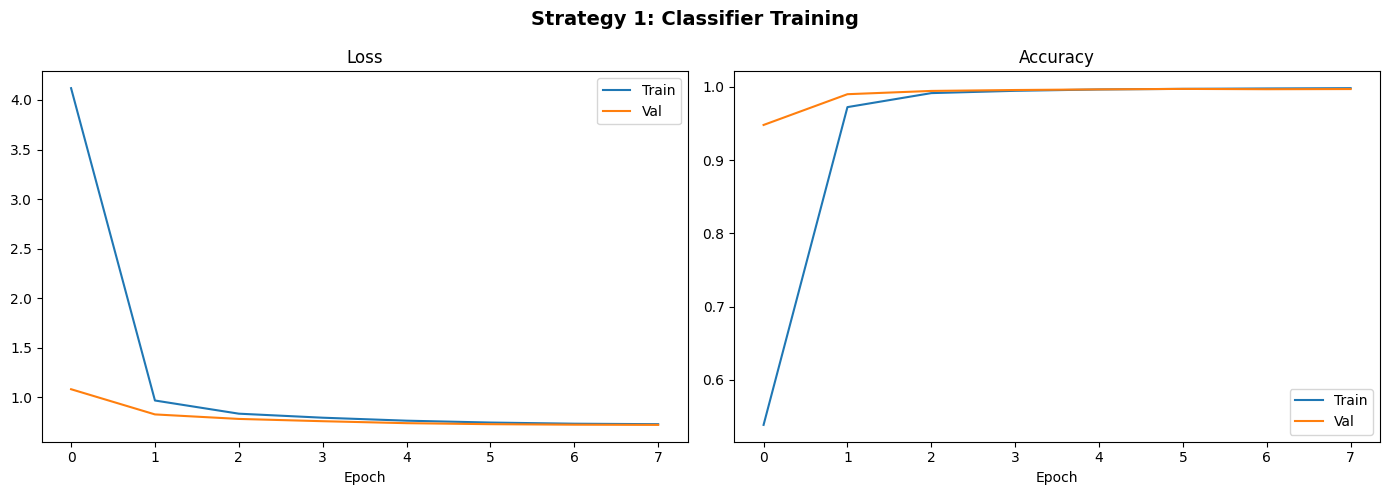

In [ ]:
# Training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history['train_loss'], label='Train'); axes[0].plot(history['val_loss'], label='Val')
axes[0].set_title('Loss'); axes[0].legend(); axes[0].set_xlabel('Epoch')
axes[1].plot(history['train_acc'], label='Train'); axes[1].plot(history['val_acc'], label='Val')
axes[1].set_title('Accuracy'); axes[1].legend(); axes[1].set_xlabel('Epoch')
plt.suptitle('Strategy 1: Classifier Training', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

---
## Step 6: Strategy 2 — Metric Learning (Embedding + Nearest Neighbor)

Learn an embedding space where visually similar symbols cluster together.  
At inference: embed the input → find nearest stored embedding → that's the answer.

This is naturally suited for one-shot learning!

In [ ]:
# Build embedding database from the trained backbone
# Use the ORIGINAL (non-augmented) images as reference embeddings

model.eval()
embedding_db = {}  # label -> embedding vector

original_files = sorted(AUG_DIR.glob('*_orig.png'))
print(f'Building embeddings for {len(original_files)} original symbols...')

embeddings_list = []
labels_list = []

with torch.no_grad():
    for fpath in tqdm(original_files, desc='Embedding'):
        img = cv2.imread(str(fpath), cv2.IMREAD_GRAYSCALE)
        if img is None: continue
        if img.shape[:2] != (IMG_H, IMG_W):
            img = cv2.resize(img, (IMG_W, IMG_H))
        img_3ch = np.stack([img]*3, axis=-1).astype(np.float32) / 255.0
        img_3ch = (img_3ch - 0.5) / 0.5  # Normalize same as training
        tensor = torch.from_numpy(img_3ch).permute(2,0,1).unsqueeze(0).to(device)

        with torch.amp.autocast('cuda', enabled=USE_AMP):
            emb = model.get_embedding(tensor)  # (1, feat_dim)
        emb = F.normalize(emb, dim=-1)  # L2 normalize

        # Extract label from filename
        parts = fpath.stem.split('_', 2)
        label = parts[1] if len(parts) >= 2 else fpath.stem
        label = label.replace('_orig', '')

        embeddings_list.append(emb.cpu())
        labels_list.append(label)

# Stack into matrix for fast similarity search
all_embeddings = torch.cat(embeddings_list, dim=0)  # (N, feat_dim)
print(f'\n✅ Embedding database: {all_embeddings.shape}')
print(f'   {len(labels_list)} symbols embedded')

Building embeddings for 15280 original symbols...


Embedding: 100%|██████████| 15280/15280 [03:12<00:00, 79.18it/s]


✅ Embedding database: torch.Size([15280, 1280])
   15280 symbols embedded


In [ ]:
# Test embedding-based retrieval accuracy
@torch.no_grad()
def embedding_predict(model, image_tensor, all_embeddings, labels_list, device, top_k=5):
    """Predict by finding nearest embedding."""
    image_tensor = image_tensor.to(device)
    with torch.amp.autocast('cuda', enabled=USE_AMP):
        emb = model.get_embedding(image_tensor)
    emb = F.normalize(emb, dim=-1).cpu()

    # Cosine similarity against all stored embeddings
    similarities = torch.mm(emb, all_embeddings.t())  # (batch, N)
    top_sims, top_indices = similarities.topk(top_k, dim=-1)

    results = []
    for i in range(emb.size(0)):
        preds = [(labels_list[idx], top_sims[i][j].item()) for j, idx in enumerate(top_indices[i].tolist())]
        results.append(preds)
    return results

# Test on validation set
print('Testing embedding retrieval on validation set...')
emb_correct = {1: 0, 3: 0, 5: 0, 10: 0}
emb_total = 0

for images, labels in tqdm(val_loader, desc='Eval Embedding', leave=False):
    results = embedding_predict(model, images, all_embeddings, labels_list, device, top_k=10)
    for i, preds in enumerate(results):
        true_label = idx_to_label[str(labels[i].item())]
        pred_labels = [p[0] for p in preds]
        for k in emb_correct:
            if true_label in pred_labels[:k]:
                emb_correct[k] += 1
        emb_total += 1

print(f'\n📊 Embedding Retrieval Accuracy:')
for k, correct in emb_correct.items():
    acc = correct / emb_total
    print(f'  Top-{k:2d}: {acc:.4f} ({acc*100:.2f}%)')

Testing embedding retrieval on validation set...



📊 Embedding Retrieval Accuracy:
  Top- 1: 0.9964 (99.64%)
  Top- 3: 0.9999 (99.99%)
  Top- 5: 1.0000 (100.00%)
  Top-10: 1.0000 (100.00%)


---
## Step 7: Strategy 3 — Image-to-Sequence (CNN → Character Decoder)

Instead of classifying into 15K classes, **spell out the word character by character**.  
The model learns: image → "a-b-a-n-d-o-n"

This works because:
- Only 26+10 output tokens (letters + digits) vs 15K classes
- Words sharing prefixes ("con-tract", "con-firm") share visual patterns
- Generalizes to unseen words!

In [ ]:
# Character vocabulary
CHARS = ' abcdefghijklmnopqrstuvwxyz0123456789-'  # space = padding/CTC blank
char_to_idx = {c: i for i, c in enumerate(CHARS)}
idx_to_char = {i: c for c, i in char_to_idx.items()}
VOCAB_SIZE = len(CHARS)
MAX_WORD_LEN = 30  # Longest word length

print(f'Character vocab: {VOCAB_SIZE} tokens')
print(f'Max word length: {MAX_WORD_LEN}')

Character vocab: 38 tokens
Max word length: 30


In [ ]:
# Seq2Seq Dataset
class Seq2SeqDataset(Dataset):
    def __init__(self, root_dir, label_to_idx, char_to_idx, transform=None, img_h=64, img_w=128, max_len=30):
        self.transform, self.char_to_idx = transform, char_to_idx
        self.img_h, self.img_w, self.max_len = img_h, img_w, max_len
        self.samples = []
        for fname in sorted(os.listdir(root_dir)):
            if not fname.endswith('.png'): continue
            parts = fname.split('_', 2)
            if len(parts) >= 2:
                rest = fname[len(parts[0])+1:].replace('.png', '')
                if '_aug' in rest: label = rest[:rest.rfind('_aug')]
                elif '_orig' in rest: label = rest[:rest.rfind('_orig')]
                else: label = rest
                if label in label_to_idx:
                    self.samples.append((os.path.join(root_dir, fname), label))
        print(f'[Seq2Seq] {len(self.samples)} images')

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        filepath, label = self.samples[idx]
        img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
        if img is None: img = np.zeros((self.img_h, self.img_w), dtype=np.uint8)
        if img.shape[:2] != (self.img_h, self.img_w):
            img = cv2.resize(img, (self.img_w, self.img_h))
        img_3ch = np.stack([img]*3, axis=-1)
        if self.transform: img_t = self.transform(image=img_3ch)['image']
        else: img_t = torch.from_numpy(img_3ch.astype(np.float32)/255.0).permute(2,0,1)

        # Encode label as character indices (CTC target)
        char_indices = [self.char_to_idx.get(c, 0) for c in label[:self.max_len]]
        target = torch.zeros(self.max_len, dtype=torch.long)
        for i, ci in enumerate(char_indices): target[i] = ci
        target_len = len(char_indices)

        return img_t, target, target_len, label

# CRNN for character-level decoding
class CharCRNN(nn.Module):
    def __init__(self, vocab_size, hidden=256, n_layers=2, dropout=0.3):
        super().__init__()
        self.cnn = timm.create_model('efficientnet_b0', pretrained=True, features_only=True)
        with torch.no_grad():
            f = self.cnn(torch.randn(1,3,64,128))[-1]
            self.c, self.h, self.w = f.shape[1], f.shape[2], f.shape[3]
        rnn_in = self.c * self.h
        self.rnn = nn.LSTM(rnn_in, hidden, n_layers, batch_first=True,
                           bidirectional=True, dropout=dropout if n_layers > 1 else 0)
        self.out = nn.Linear(hidden*2, vocab_size)
        print(f'[CharCRNN] CNN→{rnn_in}→LSTM({hidden})→{vocab_size} chars, seq_len={self.w}')

    def forward(self, x):
        f = self.cnn(x)[-1]  # (B,C,H,W)
        b,c,h,w = f.shape
        f = f.reshape(b, c*h, w).permute(0,2,1)  # (B,W,C*H)
        out, _ = self.rnn(f)  # (B,W,hidden*2)
        return F.log_softmax(self.out(out), dim=-1).permute(1,0,2)  # (T,B,V)

    def decode_greedy(self, log_probs):
        _, indices = log_probs.max(-1)  # (T,B)
        decoded = []
        for seq in indices.permute(1,0):
            chars = []
            prev = -1
            for idx in seq.tolist():
                if idx != prev and idx != 0:  # 0 = blank/space
                    chars.append(idx_to_char.get(idx, '?'))
                prev = idx
            decoded.append(''.join(chars))
        return decoded

print('✅ Seq2Seq model defined')

✅ Seq2Seq model defined


In [ ]:
# Create seq2seq dataset & loaders
seq_dataset = Seq2SeqDataset(str(AUG_DIR), label_to_idx, char_to_idx, transform=None)

n = len(seq_dataset)
n_tr, n_va = int(0.85*n), int(0.10*n)
n_te = n - n_tr - n_va
seq_train, seq_val, seq_test = random_split(seq_dataset, [n_tr, n_va, n_te],
                                             generator=torch.Generator().manual_seed(42))

class SeqTransform(Dataset):
    def __init__(self, subset, transform):
        self.subset, self.transform = subset, transform
    def __len__(self): return len(self.subset)
    def __getitem__(self, idx):
        img_t, target, tlen, label = self.subset[idx]
        img_np = (img_t.permute(1,2,0).numpy()*255).astype(np.uint8)
        img_t = self.transform(image=img_np)['image']
        return img_t, target, tlen, label

def seq_collate(batch):
    imgs, targets, tlens, labels = zip(*batch)
    return torch.stack(imgs), torch.stack(targets), torch.tensor(tlens, dtype=torch.long), labels

seq_train_dl = DataLoader(SeqTransform(seq_train, train_tf), batch_size=BATCH_SIZE,
                          shuffle=True, collate_fn=seq_collate, num_workers=NUM_WORKERS,
                          pin_memory=True, persistent_workers=True, drop_last=True)
seq_val_dl = DataLoader(SeqTransform(seq_val, val_tf), batch_size=BATCH_SIZE*2,
                        shuffle=False, collate_fn=seq_collate, num_workers=NUM_WORKERS,
                        pin_memory=True, persistent_workers=True)

print(f'Seq2Seq — Train: {len(seq_train):,} | Val: {len(seq_val):,} | Test: {len(seq_test):,}')

[Seq2Seq] 779280 images
Seq2Seq — Train: 662,388 | Val: 77,928 | Test: 38,964


In [ ]:
# Train CharCRNN
char_model = CharCRNN(vocab_size=VOCAB_SIZE, hidden=256, n_layers=2).to(device)
ctc_loss = nn.CTCLoss(blank=0, zero_infinity=True)
char_opt = optim.AdamW(char_model.parameters(), lr=5e-4, weight_decay=1e-4)
char_sched = optim.lr_scheduler.OneCycleLR(char_opt, max_lr=5e-4,
                                            steps_per_epoch=len(seq_train_dl),
                                            epochs=25, pct_start=0.1)
char_scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

char_history = {'train_loss': [], 'val_loss': []}
best_char_loss = float('inf')
char_patience = 0

print(f'Params: {sum(p.numel() for p in char_model.parameters()):,}')
print(f'Training CharCRNN for 25 epochs...')
print('=' * 70)

for epoch in range(25):
    # Train
    char_model.train(); t_loss, n_b = 0, 0
    for imgs, targets, tlens, _ in tqdm(seq_train_dl, desc=f'Ep{epoch+1}', leave=False):
        imgs = imgs.to(device, non_blocking=True)
        char_opt.zero_grad()
        with torch.amp.autocast('cuda', enabled=USE_AMP):
            lp = char_model(imgs)
            T, B = lp.size(0), lp.size(1)
            input_lens = torch.full((B,), T, dtype=torch.long)
            flat_targets = torch.cat([targets[i, :tlens[i]] for i in range(B)])
            loss = ctc_loss(lp, flat_targets, input_lens, tlens)
        if torch.isfinite(loss):
            char_scaler.scale(loss).backward()
            char_scaler.unscale_(char_opt)
            torch.nn.utils.clip_grad_norm_(char_model.parameters(), 5.0)
            char_scaler.step(char_opt); char_scaler.update()
            char_sched.step()
            t_loss += loss.item(); n_b += 1

    # Validate
    char_model.eval(); v_loss, v_b = 0, 0
    with torch.no_grad():
        for imgs, targets, tlens, _ in seq_val_dl:
            imgs = imgs.to(device, non_blocking=True)
            with torch.amp.autocast('cuda', enabled=USE_AMP):
                lp = char_model(imgs)
                T, B = lp.size(0), lp.size(1)
                input_lens = torch.full((B,), T, dtype=torch.long)
                flat_targets = torch.cat([targets[i, :tlens[i]] for i in range(B)])
                loss = ctc_loss(lp, flat_targets, input_lens, tlens)
            if torch.isfinite(loss): v_loss += loss.item(); v_b += 1

    tl, vl = t_loss/max(n_b,1), v_loss/max(v_b,1)
    char_history['train_loss'].append(tl); char_history['val_loss'].append(vl)
    print(f'Epoch {epoch+1:2d}/25 | Train CTC: {tl:.4f} | Val CTC: {vl:.4f}')

    if vl < best_char_loss:
        best_char_loss = vl; char_patience = 0
        torch.save({'model_state_dict': char_model.state_dict(),
                     'char_to_idx': char_to_idx, 'vocab_size': VOCAB_SIZE},
                    'models/char_model_best.pth')
        print(f'  ✅ Best!')
    else:
        char_patience += 1
        if char_patience >= 7: print('  ⏹ Early stopping'); break

[CharCRNN] CNN→640→LSTM(256)→38 chars, seq_len=4
Params: 7,030,946
Training CharCRNN for 25 epochs...


Epoch  1/25 | Train CTC: 0.1596 | Val CTC: 0.0371
  ✅ Best!


Epoch  2/25 | Train CTC: 0.0227 | Val CTC: 0.0170
  ✅ Best!


Epoch  3/25 | Train CTC: 0.0135 | Val CTC: 0.0091
  ✅ Best!


Epoch  4/25 | Train CTC: 0.0091 | Val CTC: 0.0105


...

Epoch 21/25 | Train CTC: 0.0000 | Val CTC: 0.0002
  ✅ Best!


Epoch 22/25 | Train CTC: 0.0000 | Val CTC: 0.0002


Epoch 23/25 | Train CTC: 0.0000 | Val CTC: 0.0002


Epoch 24/25 | Train CTC: 0.0000 | Val CTC: 0.0002


Epoch 25/25 | Train CTC: 0.0000 | Val CTC: 0.0002
  ✅ Best!


In [ ]:
# Test CharCRNN predictions
ckpt = torch.load('models/char_model_best.pth', map_location=device)
char_model.load_state_dict(ckpt['model_state_dict'])
char_model.eval()

# Grab a batch
test_dl = DataLoader(SeqTransform(seq_test, val_tf), batch_size=16, collate_fn=seq_collate)
imgs, targets, tlens, true_labels = next(iter(test_dl))

with torch.no_grad(), torch.amp.autocast('cuda', enabled=USE_AMP):
    lp = char_model(imgs.to(device))
    decoded = char_model.decode_greedy(lp)

print('CharCRNN Predictions:')
print('=' * 50)
correct = 0
for i in range(min(16, len(decoded))):
    match = '✅' if decoded[i] == true_labels[i] else '❌'
    print(f'  {match} GT: {true_labels[i]:20s} | Pred: {decoded[i]}')
    if decoded[i] == true_labels[i]: correct += 1
print(f'\nSample accuracy: {correct}/{min(16,len(decoded))}')

CharCRNN Predictions:
  ❌ GT: calcium              | Pred: mame
  ❌ GT: frantically          | Pred: fray
  ❌ GT: administratrix       | Pred: yaut
  ❌ GT: uniform              | Pred: form
  ❌ GT: trigraph             | Pred: tat
  ❌ GT: department           | Pred: toen
  ❌ GT: vital                | Pred: vial
  ❌ GT: filigree             | Pred: flag
  ❌ GT: reprisal             | Pred: pal
  ❌ GT: deer                 | Pred: dear
  ❌ GT: hieroglyphic         | Pred: hirg
  ❌ GT: crept                | Pred: gipt
  ❌ GT: ravage               | Pred: drve
  ❌ GT: magnitude            | Pred: mnto
  ❌ GT: chief                | Pred: chef
  ❌ GT: papalize             | Pred: pcy

Sample accuracy: 0/16


---
## Step 8: Ensemble Evaluation

Combine all three strategies:
1. **Classifier** → top-5 class predictions
2. **Embedding retrieval** → top-5 nearest neighbors  
3. **CharCRNN** → decoded word string

Final answer = majority vote / weighted ensemble.

In [ ]:
# Full evaluation on test set
print('Full ensemble evaluation on test set...')
print('=' * 60)

# Evaluate classifier Top-K
@torch.no_grad()
def topk_accuracy(model, loader, device, ks=[1, 3, 5, 10]):
    model.eval(); results = {k: 0 for k in ks}; total = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        with torch.amp.autocast('cuda', enabled=USE_AMP):
            outputs = model(images)
        for k in ks:
            _, topk = outputs.topk(min(k, outputs.size(1)), dim=1)
            results[k] += topk.eq(labels.unsqueeze(1)).any(1).sum().item()
        total += labels.size(0)
    return {k: v/total for k, v in results.items()}

classifier_topk = topk_accuracy(model, test_loader, device)
print('📊 Strategy 1 — Classifier:')
for k, acc in classifier_topk.items():
    print(f'  Top-{k:2d}: {acc*100:.2f}%')

print(f'\n📊 Strategy 2 — Embedding Retrieval:')
print(f'  (Results from earlier evaluation above)')

print(f'\n📊 Strategy 3 — CharCRNN:')
char_correct, char_total = 0, 0
char_model.eval()
test_seq_dl = DataLoader(SeqTransform(seq_test, val_tf), batch_size=32, collate_fn=seq_collate)
with torch.no_grad():
    for imgs, _, _, true_labels in tqdm(test_seq_dl, leave=False):
        with torch.amp.autocast('cuda', enabled=USE_AMP):
            lp = char_model(imgs.to(device))
            decoded = char_model.decode_greedy(lp)
        for d, t in zip(decoded, true_labels):
            if d == t: char_correct += 1
            char_total += 1
print(f'  Exact match: {char_correct/char_total*100:.2f}% ({char_correct}/{char_total})')

Full ensemble evaluation on test set...
📊 Strategy 1 — Classifier:
  Top- 1: 99.66%
  Top- 3: 100.00%
  Top- 5: 100.00%
  Top-10: 100.00%

📊 Strategy 2 — Embedding Retrieval:
  (Results from earlier evaluation above)

📊 Strategy 3 — CharCRNN:


  Exact match: 8.24% (3210/38964)


---
## Step 9: Generate Sentence Dataset & Test

In [ ]:
# Quick sentence generation (same as before)
LEGAL_WORDS = [w for w in ["attorney","shall","prepare","contract","within","period",
    "court","judge","claim","evidence","witness","testify","appeal","verdict",
    "guilty","defend","prosecute","settle","agree","grant","deny","motion",
    "file","record","order","rule","statute","law","right","duty","breach",
    "damage","relief","remedy","award","penalty","enforce","comply","consent",
    "notice","hearing","trial","plea","charge","sentence","convict","release",
    "bond","bail","arrest","warrant","search","seize","property","estate",
    "trust","will","deed","title","lease","rent","sell","purchase","transfer",
    "assign","negotiate","mediate","arbitrate","resolve","dispute","liable",
    "negligent","fraud","theft","crime","offense","violate","prohibit",
    "permit","license","regulate","inspect","certify","qualify","authorize",
    "appoint","elect","govern","legislate","enact","amend","repeal","ratify"]
    if w in label_to_idx]

def make_sentence_img(word_list, symbols_dict, target_h=64, gap=(15,30)):
    parts = []
    for w in word_list:
        img = symbols_dict.get(w)
        if img is None: continue
        _, b = cv2.threshold(img, 128, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
        coords = cv2.findNonZero(b)
        if coords is None: continue
        x,y,ww,hh = cv2.boundingRect(coords)
        crop = b[max(0,y-2):y+hh+2, max(0,x-2):x+ww+2]
        sc = (target_h-10)/max(crop.shape[0],1)
        parts.append(cv2.resize(crop, (max(int(crop.shape[1]*sc),5), target_h-10)))
    if not parts: return np.ones((target_h, 200), dtype=np.uint8)*255
    tw = sum(p.shape[1] for p in parts) + (len(parts)-1)*22 + 20
    canvas = np.zeros((target_h, tw), dtype=np.uint8)
    xp = 10
    for p in parts:
        yo = 5 + random.randint(-3,3)
        h,w = p.shape
        y1,y2 = max(0,yo), min(target_h,yo+h)
        x2 = min(tw, xp+w)
        canvas[y1:y2, xp:x2] = cv2.bitwise_or(canvas[y1:y2,xp:x2], p[:y2-y1,:x2-xp])
        xp += w + random.randint(*gap)
    return 255 - canvas

# Load raw symbols
raw_symbols = {}
for fp in raw_dir.rglob('*'):
    if fp.suffix.lower() in {'.png','.jpg','.jpeg'}:
        im = cv2.imread(str(fp), cv2.IMREAD_GRAYSCALE)
        if im is not None: raw_symbols[fp.stem.lower()] = im

print(f'Legal words available: {len(LEGAL_WORDS)}')
print(f'Raw symbols loaded: {len(raw_symbols)}')

# Generate sentences
random.seed(42)
sent_data = []
for i in range(2000):
    nw = random.choice([4,5,6])
    words = random.sample(LEGAL_WORDS, min(nw, len(LEGAL_WORDS)))
    img = make_sentence_img(words, raw_symbols)
    fname = f'sent_{i:05d}.png'
    cv2.imwrite(f'data/sentences/images/{fname}', img)
    sent_data.append({'filename': fname, 'words': '|'.join(words)})

with open('data/sentences/labels.csv', 'w', newline='') as f:
    w = csv.DictWriter(f, fieldnames=['filename','words']); w.writeheader(); w.writerows(sent_data)
print(f'✅ Generated {len(sent_data)} sentences')

Legal words available: 83
Raw symbols loaded: 15280
✅ Generated 2000 sentences


---
## Step 10: 📥 Download Everything

Download these to use in VSCode:

In [ ]:
# Save embedding database
torch.save({
    'embeddings': all_embeddings,
    'labels': labels_list,
}, 'models/embedding_db.pth')

# Package for download
os.makedirs('download_package', exist_ok=True)
for f in ['models/symbol_model_best.pth', 'models/char_model_best.pth',
          'models/embedding_db.pth', 'data/processed/label_to_idx.json',
          'data/processed/idx_to_label.json']:
    if os.path.exists(f): shutil.copy(f, 'download_package/')

shutil.make_archive('pitman_trained_models', 'zip', 'download_package')

print('✅ Package ready!')
for f in os.listdir('download_package'):
    sz = os.path.getsize(f'download_package/{f}') / 1024**2
    print(f'  {f}: {sz:.1f} MB')

✅ Package ready!
  symbol_model_best.pth: 80.7 MB
  char_model_best.pth: 27.1 MB
  idx_to_label.json: 0.3 MB
  label_to_idx.json: 0.3 MB
  embedding_db.pth: 37.6 MB


In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Copy models to Drive (instant, no download needed)
import shutil
os.makedirs('/content/drive/MyDrive/pitman_models', exist_ok=True)

shutil.copy('models/symbol_model_best.pth', '/content/drive/MyDrive/pitman_models/')
shutil.copy('models/embedding_db.pth', '/content/drive/MyDrive/pitman_models/')
shutil.copy('data/processed/label_to_idx.json', '/content/drive/MyDrive/pitman_models/')
shutil.copy('data/processed/idx_to_label.json', '/content/drive/MyDrive/pitman_models/')

# Skip char_model — only 8% accuracy, not useful
print('✅ Saved to Google Drive → pitman_models/')
!ls -lh /content/drive/MyDrive/pitman_models/

Mounted at /content/drive
✅ Saved to Google Drive → pitman_models/
total 119M
-rw------- 1 root root  38M Apr  1 10:08 embedding_db.pth
-rw------- 1 root root 300K Apr  1 10:08 idx_to_label.json
-rw------- 1 root root 271K Apr  1 10:08 label_to_idx.json
-rw------- 1 root root  81M Apr  1 10:08 symbol_model_best.pth
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Saved to Google Drive → pitman_models/
total 119M
-rw------- 1 root root  38M Apr  1 10:08 embedding_db.pth
-rw------- 1 root root 300K Apr  1 10:08 idx_to_label.json
-rw------- 1 root root 271K Apr  1 10:08 label_to_idx.json
-rw------- 1 root root  81M Apr  1 10:08 symbol_model_best.pth


In [ ]:
import shutil

dest = '/content/drive/MyDrive/pitman_models'
os.makedirs(dest, exist_ok=True)

# All 3 models
shutil.copy('models/symbol_model_best.pth', dest)
shutil.copy('models/embedding_db.pth', dest)
shutil.copy('models/char_model_best.pth', dest)

# Label maps
shutil.copy('data/processed/label_to_idx.json', dest)
shutil.copy('data/processed/idx_to_label.json', dest)

# Sentence dataset (images + labels)
sent_dest = f'{dest}/sentences'
os.makedirs(sent_dest, exist_ok=True)
shutil.copy('data/sentences/labels.csv', sent_dest)
shutil.copytree('data/sentences/images', f'{sent_dest}/images', dirs_exist_ok=True)

print('✅ Everything saved to Drive!')
!ls -lh {dest}/
!echo "---"
!echo "Sentence images:"
!ls {sent_dest}/images/ | wc -l
!echo "Labels:"
!head -5 {sent_dest}/labels.csv

✅ Everything saved to Drive!
total 146M
-rw------- 1 root root  28M Apr  1 10:15 char_model_best.pth
-rw------- 1 root root  38M Apr  1 10:15 embedding_db.pth
-rw------- 1 root root 300K Apr  1 10:15 idx_to_label.json
-rw------- 1 root root 271K Apr  1 10:15 label_to_idx.json
drwx------ 3 root root 4.0K Apr  1 10:15 sentences
-rw------- 1 root root  81M Apr  1 10:15 symbol_model_best.pth
---
Sentence images:
2000
Labels:
filename,words
sent_00000.png,defend|contract|consent|remedy|breach|agree
sent_00001.png,statute|violate|title|breach|assign|authorize
sent_00002.png,appeal|seize|verdict|arrest
sent_00003.png,prosecute|seize|testify|permit|trial|warrant


Testing sentence segmentation + recognition
✅ Sentence 1:
   GT:   defend contract consent remedy breach agree
   Pred: defend contract consent remedy breach agree

✅ Sentence 2:
   GT:   statute violate title breach assign authorize
   Pred: statute violate title breach assign authorize

✅ Sentence 3:
   GT:   appeal seize verdict arrest
   Pred: appeal seize verdict arrest

✅ Sentence 4:
   GT:   prosecute seize testify permit trial warrant
   Pred: prosecute seize testify permit trial warrant

✅ Sentence 5:
   GT:   consent negotiate repeal warrant motion
   Pred: consent negotiate repeal warrant motion

✅ Sentence 6:
   GT:   mediate seize comply repeal
   Pred: mediate seize comply repeal

✅ Sentence 7:
   GT:   will comply claim duty inspect
   Pred: will comply claim duty inspect

✅ Sentence 8:
   GT:   license offense penalty qualify lease legislate
   Pred: license offense penalty qualify lease legislate

✅ Sentence 9:
   GT:   lease appoint claim property seize repeal
   Pred

/tmp/ipykernel_880/1434395089.py:127: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


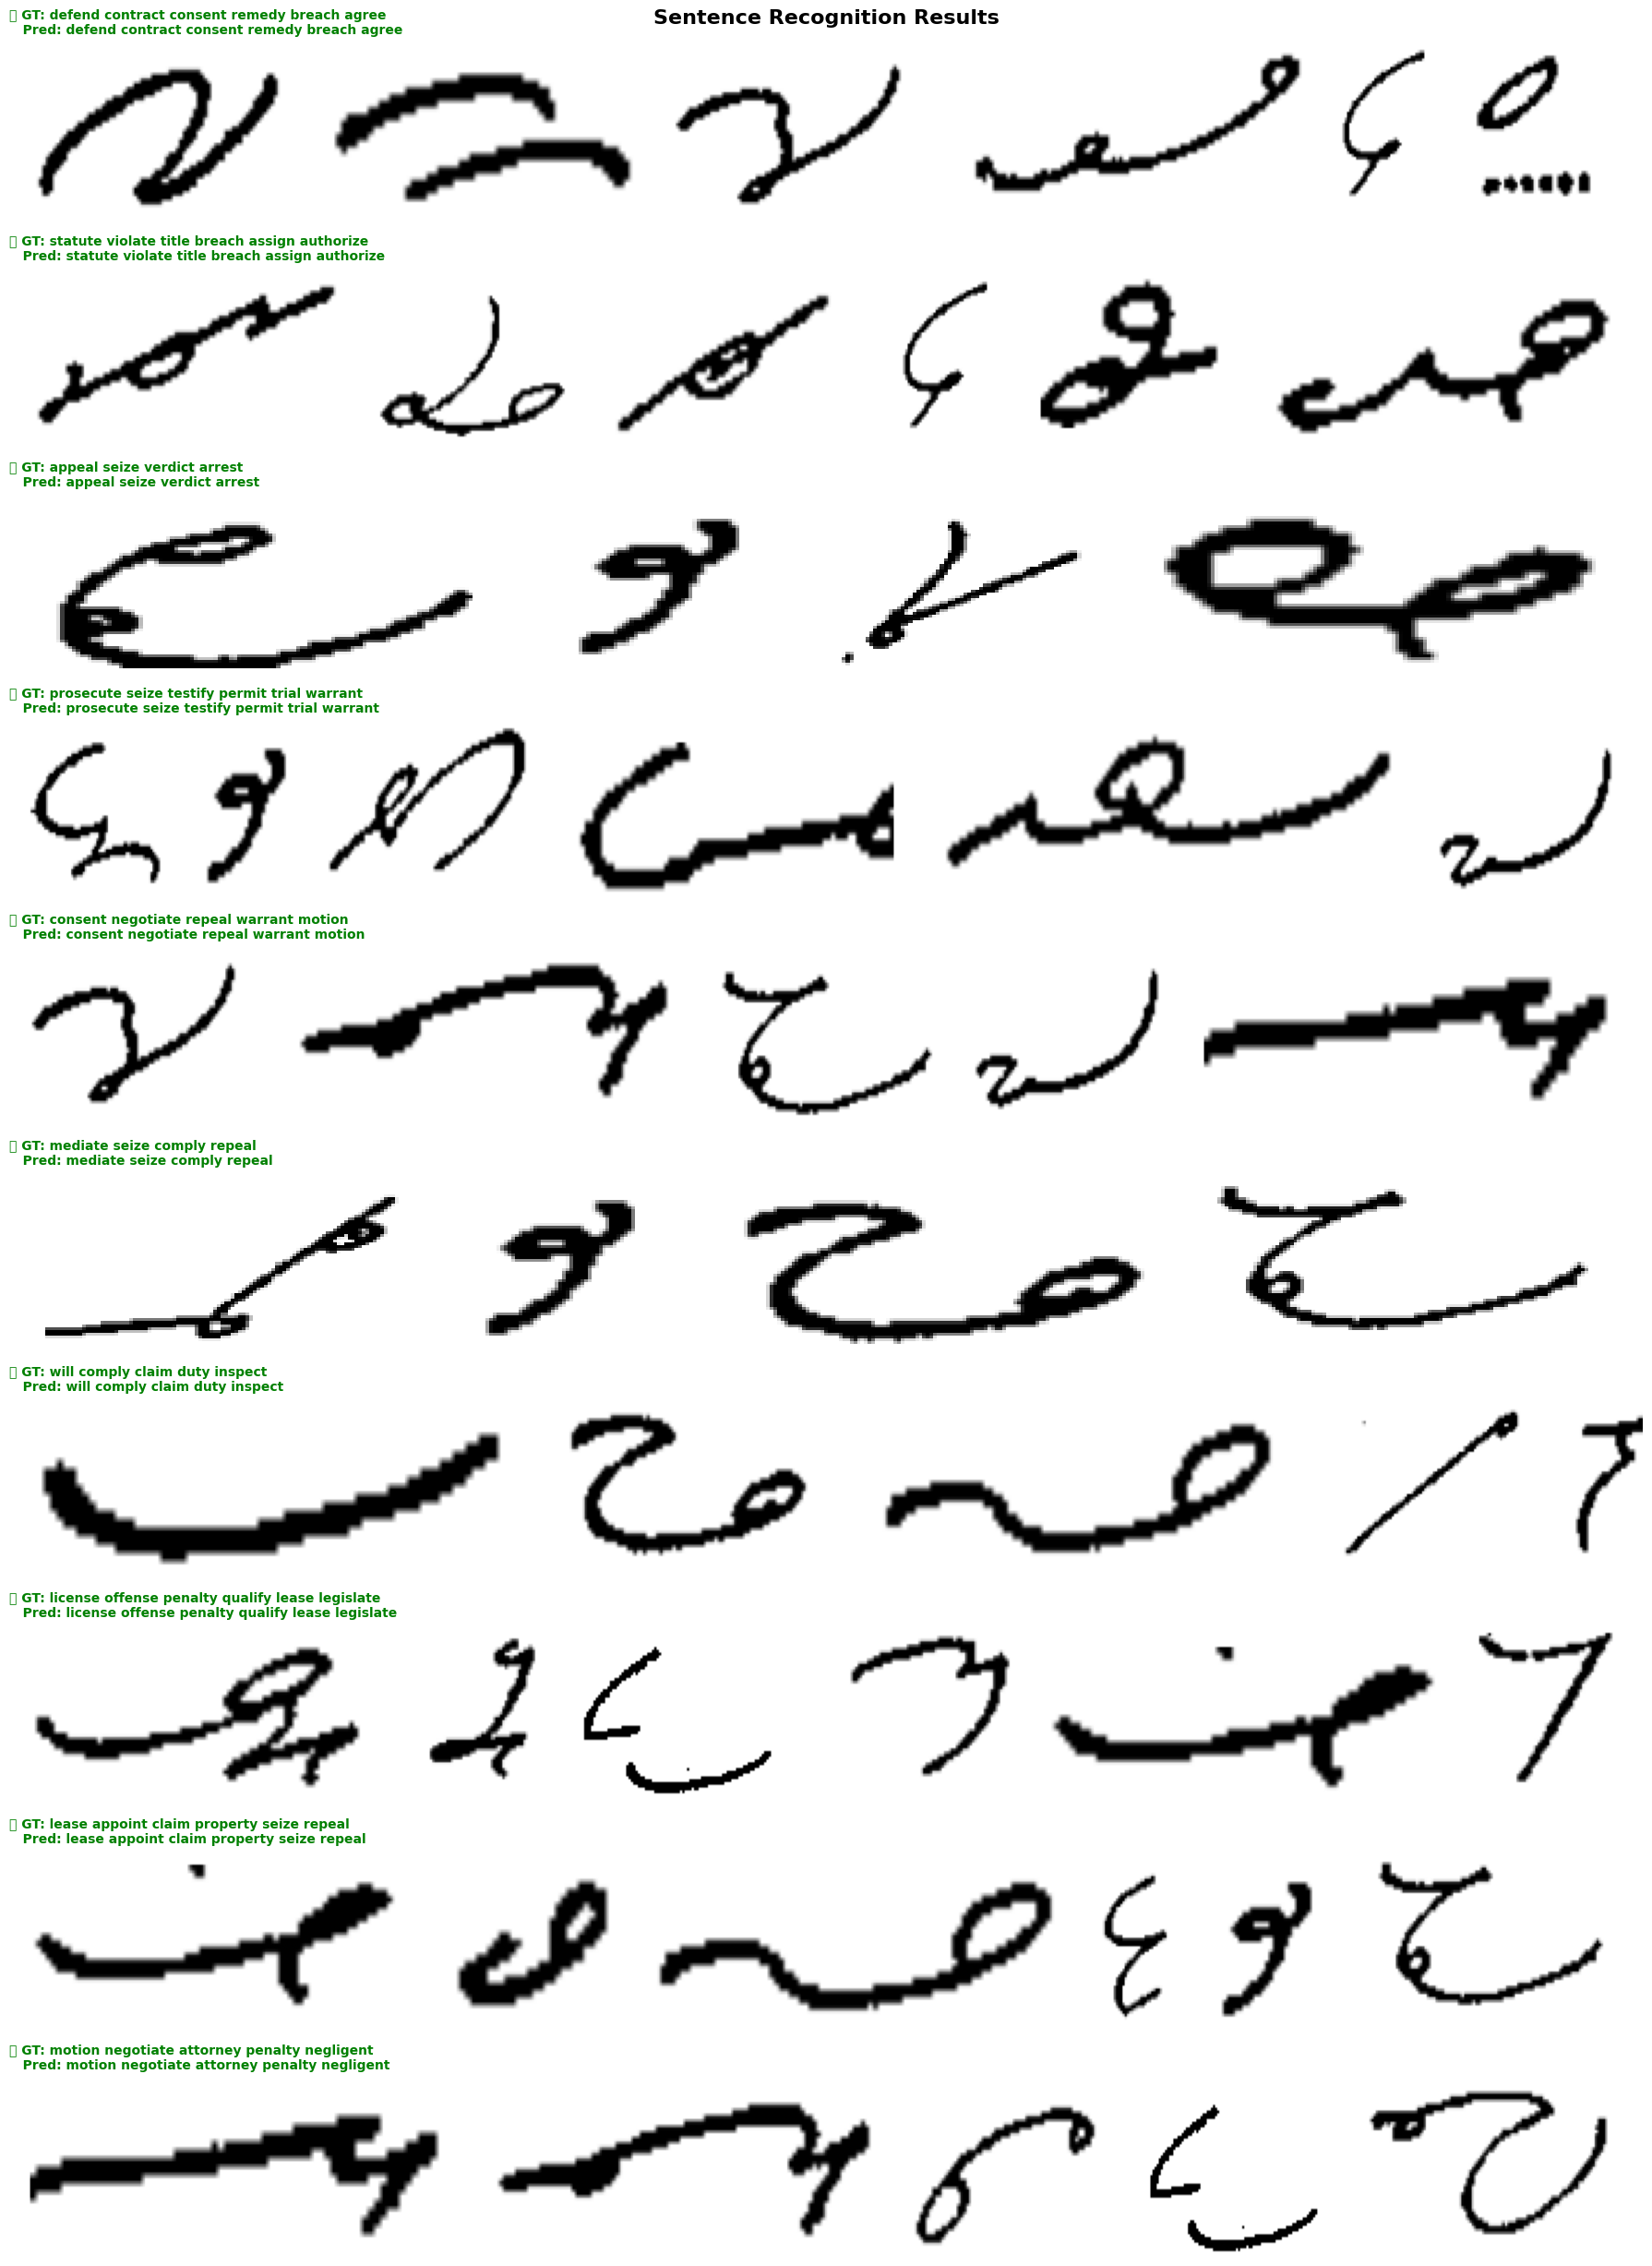


📊 Word-level accuracy: 53/53 = 100.00%


In [ ]:
# ============================================
# Test Sentence Images — Segment + Recognize
# ============================================
import pandas as pd

# Load sentence labels
sent_df = pd.read_csv('data/sentences/labels.csv')

def segment_sentence(img, min_gap=10):
    """Split sentence image into individual symbols."""
    if len(img.shape) == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    binary = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv2.THRESH_BINARY_INV, 11, 5)
    # Connect broken strokes
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 1))
    connected = cv2.dilate(binary, kernel, iterations=1)

    # Vertical projection
    v_proj = np.sum(connected, axis=0)
    threshold = v_proj.max() * 0.02
    is_ink = v_proj > threshold

    # Find symbol boundaries
    segments = []
    in_sym = False
    start = 0
    for x in range(len(is_ink)):
        if is_ink[x] and not in_sym:
            start = x; in_sym = True
        elif not is_ink[x] and in_sym:
            if segments and (start - segments[-1][1]) < min_gap:
                segments[-1] = (segments[-1][0], x)
            else:
                segments.append((start, x))
            in_sym = False
    if in_sym:
        if segments and (start - segments[-1][1]) < min_gap:
            segments[-1] = (segments[-1][0], len(is_ink))
        else:
            segments.append((start, len(is_ink)))

    return [img[:, max(0,x1-3):min(img.shape[1],x2+3)] for x1, x2 in segments if x2-x1 > 5]

def recognize_symbol(sym_img, model, idx_to_label, device):
    """Recognize a single segmented symbol."""
    # Preprocess same as training
    binary = cv2.adaptiveThreshold(sym_img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv2.THRESH_BINARY_INV, 11, 5)
    coords = cv2.findNonZero(binary)
    if coords is not None:
        x, y, w, h = cv2.boundingRect(coords)
        p = 5
        binary = binary[max(0,y-p):y+h+p, max(0,x-p):x+w+p]

    h, w = binary.shape
    scale = min(64/h, 128/w)
    nh, nw = int(h*scale), int(w*scale)
    resized = cv2.resize(binary, (nw, nh))
    result = np.zeros((64, 128), dtype=np.uint8)
    yy, xx = (64-nh)//2, (128-nw)//2
    result[yy:yy+nh, xx:xx+nw] = resized

    img_3ch = np.stack([result]*3, axis=-1).astype(np.float32) / 255.0
    img_3ch = (img_3ch - 0.5) / 0.5
    tensor = torch.from_numpy(img_3ch).permute(2,0,1).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad(), torch.amp.autocast('cuda', enabled=USE_AMP):
        logits = model(tensor)
        probs = F.softmax(logits, dim=-1)
        top_probs, top_idx = probs.topk(3, dim=-1)

    preds = [(idx_to_label[str(idx.item())], prob.item())
             for idx, prob in zip(top_idx[0], top_probs[0])]
    return preds

# ============================================
# Test on 10 sentence images
# ============================================
print('Testing sentence segmentation + recognition')
print('=' * 70)

correct_words = 0
total_words = 0

fig, axes = plt.subplots(10, 1, figsize=(18, 25))

for i in range(10):
    row = sent_df.iloc[i]
    img = cv2.imread(f"data/sentences/images/{row['filename']}", cv2.IMREAD_GRAYSCALE)
    gt_words = row['words'].split('|')

    # Segment
    symbols = segment_sentence(img)

    # Recognize each symbol
    pred_words = []
    for sym in symbols:
        preds = recognize_symbol(sym, model, idx_to_label, device)
        pred_words.append(preds[0][0])  # Top-1 prediction

    # Compare
    gt_str = ' '.join(gt_words)
    pred_str = ' '.join(pred_words)

    # Count word-level accuracy
    for j in range(min(len(gt_words), len(pred_words))):
        if gt_words[j] == pred_words[j]:
            correct_words += 1
        total_words += 1

    match = '✅' if gt_str == pred_str else '❌'

    # Visualize
    axes[i].imshow(img, cmap='gray', aspect='auto')
    axes[i].set_title(f'{match} GT: {gt_str}\n   Pred: {pred_str}', fontsize=10,
                       fontweight='bold', loc='left', color='green' if gt_str == pred_str else 'red')
    axes[i].axis('off')

    print(f'{match} Sentence {i+1}:')
    print(f'   GT:   {gt_str}')
    print(f'   Pred: {pred_str}')
    print()

plt.suptitle('Sentence Recognition Results', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

word_acc = correct_words / max(total_words, 1)
print(f'\n📊 Word-level accuracy: {correct_words}/{total_words} = {word_acc*100:.2f}%')

In [ ]:
import os

drive_path = '/content/drive/MyDrive/pitman_models'

print('📁 Files in Google Drive:')
print('=' * 50)
for root, dirs, files in os.walk(drive_path):
    for f in files:
        fp = os.path.join(root, f)
        size = os.path.getsize(fp) / 1024**2
        print(f'  {fp.replace(drive_path, "")}  ({size:.1f} MB)')

print('\n📁 Files in Colab (will be LOST when session ends):')
print('=' * 50)
for folder in ['models', 'data/processed', 'data/augmented', 'data/sentences']:
    if os.path.exists(folder):
        count = len(os.listdir(folder))
        print(f'  {folder}/ → {count} files')
    else:
        print(f'  {folder}/ → NOT FOUND')

📁 Files in Google Drive:
  /symbol_model_best.pth  (80.7 MB)
  /embedding_db.pth  (37.6 MB)
  /label_to_idx.json  (0.3 MB)
  /idx_to_label.json  (0.3 MB)
  /char_model_best.pth  (27.1 MB)
  /sentences/labels.csv  (0.1 MB)
  /sentences/images/sent_00296.png  (0.0 MB)
  /sentences/images/sent_01651.png  (0.0 MB)
  /sentences/images/sent_01642.png  (0.0 MB)
  /sentences/images/sent_01949.png  (0.0 MB)
  /sentences/images/sent_00959.png  (0.0 MB)
  /sentences/images/sent_00671.png  (0.0 MB)
  /sentences/images/sent_01326.png  (0.0 MB)
  /sentences/images/sent_01405.png  (0.0 MB)
  /sentences/images/sent_01786.png  (0.0 MB)
  /sentences/images/sent_01643.png  (0.0 MB)
  /sentences/images/sent_00213.png  (0.0 MB)
  /sentences/images/sent_01369.png  (0.0 MB)
  /sentences/images/sent_01065.png  (0.0 MB)
  /sentences/images/sent_00566.png  (0.0 MB)
  /sentences/images/sent_01573.png  (0.0 MB)
  /sentences/images/sent_00705.png  (0.0 MB)
  /sentences/images/sent_00865.png  (0.0 MB)
  /sentences/

In [ ]:
# Save everything important to Drive
import shutil

dest = '/content/drive/MyDrive/pitman_models'

# Save sentence dataset (if not already saved)
if not os.path.exists(f'{dest}/sentences'):
    shutil.copytree('data/sentences', f'{dest}/sentences')
    print('✅ Sentence dataset saved')

# Save label maps (if not already saved)
for f in ['data/processed/label_to_idx.json', 'data/processed/idx_to_label.json']:
    if os.path.exists(f):
        shutil.copy(f, dest)

# Save all 3 models (if not already saved)
for f in ['models/symbol_model_best.pth', 'models/embedding_db.pth', 'models/char_model_best.pth']:
    if os.path.exists(f):
        shutil.copy(f, dest)

print('\n✅ Everything backed up to Drive!')
print('   Safe to close Colab now.')


✅ Everything backed up to Drive!
   Safe to close Colab now.


---
## ✅ Done!

### What you trained:
| Model | Purpose | How it works |
|-------|---------|-------------|
| `symbol_model_best.pth` | Classifier (15K classes) | EfficientNet → class prediction |
| `embedding_db.pth` | Nearest neighbor retrieval | Compare embeddings for similarity |
| `char_model_best.pth` | Spell out the word | CNN → BiLSTM → CTC → characters |

### Next Steps (VSCode):
1. Place models in `models/` folder
2. Run `python server.py`
3. Open `frontend/app.html`
4. Upload shorthand → get meaning!